# GiftIQ – RFM Customer Segmentation

**Business question:** Which customers drive the most revenue, and which valuable customers are we about to lose?

This notebook takes cleaned online-retail transactions (a UK gift retailer, Dec 2009 – Dec 2011), scores every customer on **Recency, Frequency and Monetary** value, groups them into **6 segments**, flags **churn**, and exports two tables for the Power BI dashboard.

| Step | Output |
|---|---|
| 1. Load & check data | Clean transaction table |
| 2. Explore | Revenue trend and country mix |
| 3. RFM | Recency, Frequency, Monetary per customer |
| 4. Score & segment | 1–5 scores, 6 segments, churn flag |
| 5. Export | `Sales.csv` (fact) and `Customers.csv` (dimension) |

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.float_format", "{:,.2f}".format)

REPO = Path.cwd().parent
RAW_FILE = REPO / "data" / "raw" / "EcommerceDashboardData.xlsx"
OUT_DIR = REPO / "data" / "processed"
CHURN_DAYS = 90

# GiftIQ brand colours
PLUM, GOLD, SOFT_PLUM, RED = "#5B2A86", "#F2A541", "#9C7BC0", "#D64550"

## 2. Load the data

In [2]:
cols = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Customer_ID", "Country"]
df = pd.read_excel(RAW_FILE, usecols=cols)

print(f"Rows: {len(df):,}")
print("Date range:", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
df.head()

Rows: 779,495
Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer_ID,Country
0,553149,21755,LOVE BUILDING BLOCK WORD,6,2011-05-13 14:16:00,5.95,14226,United Kingdom
1,553149,21983,PACK OF 12 BLUE PAISLEY TISSUES,24,2011-05-13 14:16:00,0.29,14226,United Kingdom
2,553149,21984,PACK OF 12 PINK PAISLEY TISSUES,24,2011-05-13 14:16:00,0.29,14226,United Kingdom
3,553149,22831,WHITE BROCANTE SOAP DISH,6,2011-05-13 14:16:00,2.95,14226,United Kingdom
4,553149,22986,GINGHAM ROSE WRAP,25,2011-05-13 14:16:00,0.42,14226,United Kingdom


In [3]:
# Data quality checks
print("Missing values per column:")
print(df.isna().sum())
print(f"\nRows with Quantity <= 0: {(df['Quantity'] <= 0).sum():,}")
print(f"Rows with Price <= 0:    {(df['Price'] <= 0).sum():,}")
dup_keys = ["Invoice", "StockCode", "Quantity", "InvoiceDate", "Price", "Customer_ID"]
print(f"Duplicate rows:          {df.duplicated(dup_keys).sum():,}")

Missing values per column:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer_ID    0
Country        0
dtype: int64

Rows with Quantity <= 0: 0
Rows with Price <= 0:    88


Duplicate rows:          2


## 3. Clean

Keep only real sales: positive quantity, positive price, no duplicate lines. Then calculate **Revenue = Quantity × Price** for each line.

In [4]:
sales = df[(df["Quantity"] > 0) & (df["Price"] > 0)].drop_duplicates(dup_keys).copy()
sales["Revenue"] = (sales["Quantity"] * sales["Price"]).round(2)

print(f"Rows after cleaning: {len(sales):,}  (removed {len(df) - len(sales):,})")
print(f"Customers: {sales['Customer_ID'].nunique():,}")
print(f"Orders:    {sales['Invoice'].nunique():,}")
print(f"Countries: {sales['Country'].nunique()}")
print(f"Revenue:   {sales['Revenue'].sum():,.0f}")

Rows after cleaning: 779,405  (removed 90)
Customers: 5,878
Orders:    36,969
Countries: 41
Revenue:   17,374,252


## 4. Explore

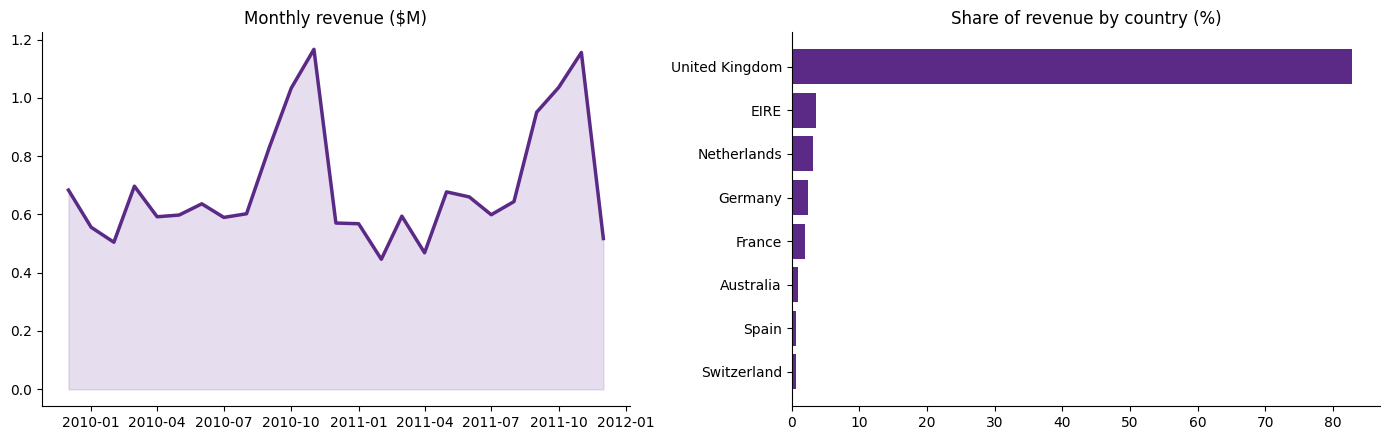

Revenue share by quarter (%): {1: 19.4, 2: 20.9, 3: 24.3, 4: 35.5}


In [5]:
monthly = sales.set_index("InvoiceDate").resample("MS")["Revenue"].sum() / 1e6
top_countries = sales.groupby("Country")["Revenue"].sum().nlargest(8) / sales["Revenue"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(monthly.index, monthly.values, color=PLUM, linewidth=2.5)
axes[0].fill_between(monthly.index, monthly.values, color=SOFT_PLUM, alpha=0.25)
axes[0].set_title("Monthly revenue ($M)")
axes[1].barh(top_countries.index[::-1], top_countries.values[::-1], color=PLUM)
axes[1].set_title("Share of revenue by country (%)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

q_share = sales.groupby(sales["InvoiceDate"].dt.quarter)["Revenue"].sum() / sales["Revenue"].sum() * 100
print("Revenue share by quarter (%):", q_share.round(1).to_dict())

## 5. Calculate Recency, Frequency and Monetary

- **Snapshot date** = the day after the last invoice
- **Recency** = days since the customer's last purchase (lower is better)
- **Frequency** = number of separate orders (unique invoices)
- **Monetary** = total amount spent

In [6]:
snapshot_date = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date.date())

rfm = sales.groupby("Customer_ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
).reset_index()

rfm.describe()

Snapshot date: 2011-12-10


,Customer_ID,Recency,Frequency,Monetary
count,"5,878.00","5,878.00","5,878.00","5,878.00"
mean,"15,315.31",200.87,6.29,"2,955.81"
std,"1,715.57",209.35,13.01,"14,440.29"
min,"12,346.00",0.00,1.00,2.95
25%,"13,833.25",25.00,1.00,342.28
50%,"15,314.50",95.00,3.00,867.74
75%,"16,797.75",379.00,7.00,"2,248.30"
max,"18,287.00",738.00,398.00,"580,987.04"


## 6. Score each customer from 1 to 5

`pd.qcut` splits customers into 5 equal groups, from the lowest value to the highest.

- **Recency:** a low value is good, so labels are reversed `[5,4,3,2,1]`.
- **Frequency and Monetary:** a high value is good, so labels are `[1,2,3,4,5]`.
- Many customers have exactly 1 order, which makes the bin edges equal. Ranking first with `rank(method="first")` breaks those ties.

In [7]:
rfm["R_Score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Score"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)

# Sanity check: higher F_Score must mean more orders
rfm.groupby("F_Score")["Frequency"].agg(["min", "max", "mean"])

,min,max,mean
F_Score,,,
1,1,1,1.00
2,1,2,1.62
3,2,4,3.07
4,4,8,5.77
5,8,398,19.99


## 7. Assign segments and churn

| Segment | Rule | Meaning |
|---|---|---|
| Champions | R ≥ 4, F ≥ 4, M ≥ 4 | Bought recently, buy often, spend the most |
| Loyal | R ≥ 3, F ≥ 3 | Regular, reliable buyers |
| At Risk | R ≤ 2, F ≥ 3 | Used to buy often but haven't come back |
| New | R ≥ 4, F ≤ 2 | Bought recently for the first time or two |
| Needs Attention | R = 3, F ≤ 2 | Average recency, few orders |
| Lost | everything else | Long gone and low value |

A customer is **churned** if they haven't bought anything for more than 90 days.

In [8]:
def segment_customer(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"
    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "New"
    elif row["R_Score"] == 3 and row["F_Score"] <= 2:
        return "Needs Attention"
    else:
        return "Lost"


rfm["Segment"] = rfm.apply(segment_customer, axis=1)
rfm["IsChurned"] = rfm["Recency"] > CHURN_DAYS
rfm["Monetary"] = rfm["Monetary"].round(2)

print(f"Churn rate: {rfm['IsChurned'].mean():.1%}")
rfm["Segment"].value_counts()

Churn rate: 50.9%


Segment
Lost               1522
Loyal              1415
Champions          1291
At Risk             821
New                 441
Needs Attention     388
Name: count, dtype: int64

## 8. Segment summary

In [9]:
SEGMENTS = ["Champions", "Loyal", "At Risk", "New", "Needs Attention", "Lost"]

summary = rfm.groupby("Segment").agg(
    Customers=("Customer_ID", "count"),
    Revenue=("Monetary", "sum"),
    Avg_Value=("Monetary", "mean"),
    Avg_R=("R_Score", "mean"),
    Avg_F=("F_Score", "mean"),
    Avg_M=("M_Score", "mean"),
    Churn_Pct=("IsChurned", "mean"),
).reindex(SEGMENTS)
summary["Customer_Pct"] = summary["Customers"] / summary["Customers"].sum() * 100
summary["Revenue_Pct"] = summary["Revenue"] / summary["Revenue"].sum() * 100
summary["Churn_Pct"] *= 100
summary

,Customers,Revenue,Avg_Value,Avg_R,Avg_F,Avg_M,Churn_Pct,Customer_Pct,Revenue_Pct
Segment,,,,,,,,,
Champions,1291,"11,836,095.89","9,168.16",4.58,4.69,4.65,0.00,21.96,68.12
Loyal,1415,"2,700,753.93","1,908.66",3.65,3.65,3.36,31.45,24.07,15.54
At Risk,821,"1,586,359.12","1,932.23",1.67,3.52,3.22,100.00,13.97,9.13
New,441,"392,021.57",888.94,4.39,1.62,1.98,0.00,7.50,2.26
Needs Attention,388,"205,137.22",528.70,3.00,1.50,1.99,51.80,6.60,1.18
Lost,1522,"653,884.67",429.62,1.41,1.46,1.70,100.00,25.89,3.76


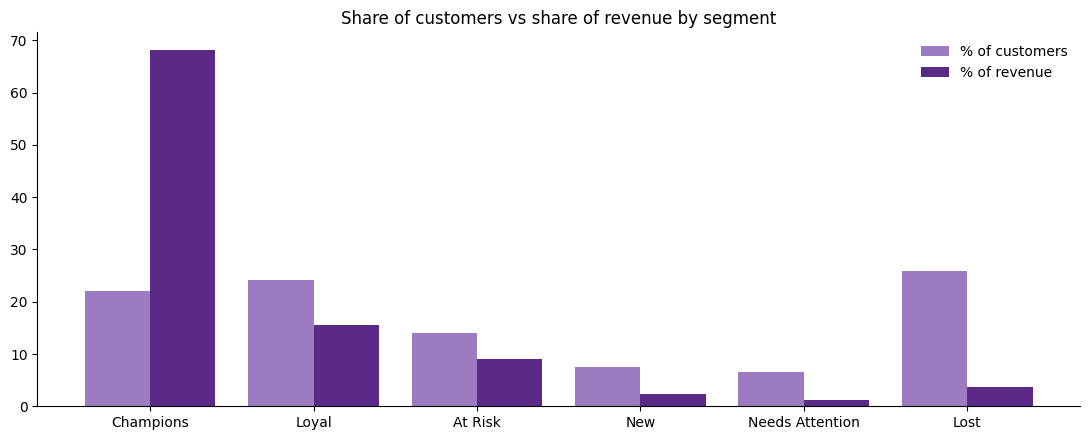

Champions: 22.0% of customers -> 68.1% of revenue ($11.8M)
At Risk:   821 customers worth $1.59M


In [10]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = range(len(SEGMENTS))
ax.bar([i - 0.2 for i in x], summary["Customer_Pct"], 0.4, label="% of customers", color=SOFT_PLUM)
ax.bar([i + 0.2 for i in x], summary["Revenue_Pct"], 0.4, label="% of revenue", color=PLUM)
ax.set_xticks(list(x), SEGMENTS)
ax.set_title("Share of customers vs share of revenue by segment")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

champ = summary.loc["Champions"]
risk = summary.loc["At Risk"]
print(f"Champions: {champ['Customer_Pct']:.1f}% of customers -> {champ['Revenue_Pct']:.1f}% of revenue (${champ['Revenue']/1e6:.1f}M)")
print(f"At Risk:   {int(risk['Customers']):,} customers worth ${risk['Revenue']/1e6:.2f}M")

## 9. Validation checks

In [11]:
assert rfm["Customer_ID"].is_unique, "Duplicate customers"
assert len(rfm) == sales["Customer_ID"].nunique(), "Customer count mismatch"
assert abs(rfm["Monetary"].sum() - sales["Revenue"].sum()) < 1, "Revenue doesn't reconcile"
assert rfm[["R_Score", "F_Score", "M_Score"]].isin([1, 2, 3, 4, 5]).all().all(), "Score outside 1-5"
assert summary["Customers"].sum() == len(rfm), "Segments don't cover every customer"
print("All checks passed")

All checks passed


## 10. Export for Power BI

Two tables for a **star schema**: `Sales` (one row per invoice line) and `Customers` (one row per customer). Joined on `Customer_ID` in Power BI.

In [12]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
sales_cols = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Revenue", "Customer_ID", "Country"]
sales[sales_cols].to_csv(OUT_DIR / "Sales.csv", index=False)
rfm.to_csv(OUT_DIR / "Customers.csv", index=False)
print(f"Sales.csv:     {len(sales):,} rows")
print(f"Customers.csv: {len(rfm):,} rows")

Sales.csv:     779,405 rows
Customers.csv: 5,878 rows


## Key insights

1. **A small group drives most revenue.** Champions are about 22% of customers but bring in about 68% of revenue ($11.8M of $17.4M).
2. **Half the customer base has gone quiet.** About 51% of customers haven't bought in 90+ days.
3. **$1.59M is at risk.** 821 At Risk customers used to buy often and spend well, but haven't come back. They are the best target for a win-back campaign.
4. **Gift-season peak.** Revenue climbs from September and peaks in November. Q4 is about 35% of yearly revenue, so campaigns should start before September.
5. **Mostly UK.** The United Kingdom brings in about 83% of revenue, which leaves room to grow in other countries.

### Recommendations
- **Champions:** loyalty perks and early access to new collections.
- **At Risk:** personalised win-back offers before the Q4 season.
- **New:** a welcome series that pushes a second purchase.
- **Lost:** low-cost reactivation emails only.